# Example for oxygen dose calculation with z* kernels (mMKM) using pencilbeam engine.

This example demonstrates how to perform an oxygen ion dose calculation and optimization
with the z* kernel formalism, evaluating the mMKM z* kernels (saturation-corrected z1D) of
the Generic oxygen machine as alpha = alpha_0 + beta_0 * z* and beta = beta_0.

To display this script in a Jupyter Notebook, you need to install jupytext via pip and run the following command.
This will create a .ipynb file in the same directory:

```bash
pip install jupytext
jupytext --to notebook path/to/this/file/pencilbeam_oxygen_MKM.py

In [1]:
# Import necessary libraries
import logging

import numpy as np

from pyRadPlan import (
    IonPlan,
    load_tg119,
    generate_stf,
    calc_dose_influence,
    fluence_optimization,
    plot_multiple_slices,
)

from pyRadPlan.optimization.objectives import SquaredDeviation, SquaredOverdosing, MeanDose
from pyRadPlan.gui import launch_viewer, GUI_AVAILABLE
from pyRadPlan.biology.tissues import MKMTissueProperties

logging.basicConfig(level=logging.INFO)

In [2]:
# Load TG119 (provided within pyRadPlan)
ct, cst = load_tg119()

In this section, we create an oxygen ion therapy plan with biological effect calculation.

In [3]:
# Create a plan object
pln = IonPlan(radiation_mode="oxygen", machine="Generic")
pln.bio_model = "zstar_kernels"  # former identifier: "MKM"
pln.prop_stf = {"bixel_width": 4}
pln.prop_dose_calc = {"dose_grid": {"resolution": {"x": 3, "y": 3, "z": 3}}}

pln.prop_opt = {"solver": "scipy"}

# mMKM tissue, the provenance of the machine's z* kernels: r_nucleus / r_domain select its
# z* kernel tissue class ("Generic_MKM"), alpha_0 / beta_0 describe the tissue itself.
# alpha_x / beta_x are not given, so they are estimated from alpha_0, beta_0 and r_domain.
mmkm_cell = MKMTissueProperties(
    model="mMKM", r_nucleus=3.9, r_domain=0.32, alpha_0=0.172, beta_0=0.0615
)
for voi in cst.vois:
    voi.tissue_properties = mmkm_cell

# Optimization
cst.vois[0].objectives = [SquaredOverdosing(priority=10.0, d_max=1.0)]  # OAR
cst.vois[1].objectives = [SquaredDeviation(priority=100.0, d_ref=3.0)]  # Target
cst.vois[2].objectives = [
    MeanDose(priority=1.0, d_ref=0.0),
    SquaredOverdosing(priority=10.0, d_max=2.0),
]  # BODY

In [4]:
# Generate Steering Geometry ("stf")
stf = generate_stf(ct, cst, pln)

In [5]:
# Calculate Dose Influence Matrix ("dij")
dij = calc_dose_influence(ct, cst, stf, pln)

In [6]:
# Optimize
fluence = fluence_optimization(ct, cst, stf, dij, pln)

# Result
result = dij.compute_result_ct_grid(fluence)

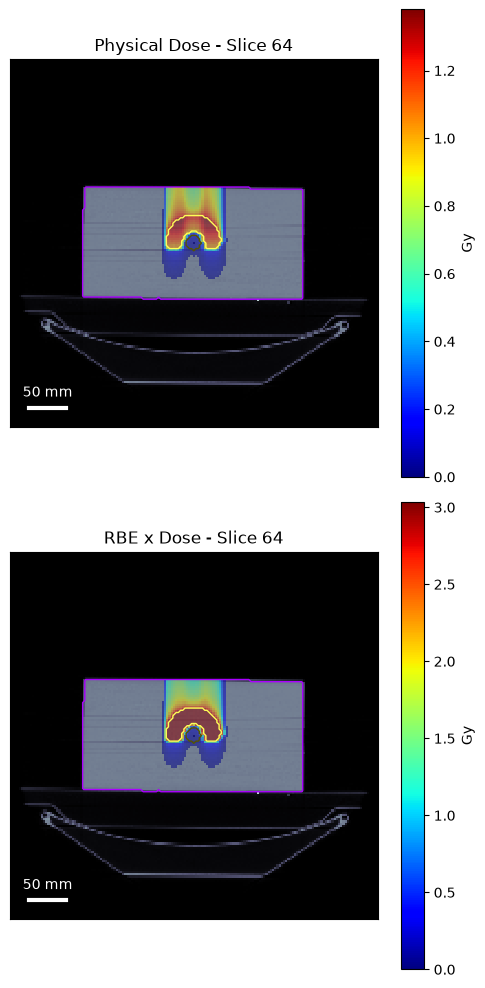

In [7]:
if GUI_AVAILABLE:
    # Use the GUI if [gui] dependencies are installed
    launch_viewer(ct, cst, result)
else:
    # Choose slices to visualize
    view_slice = [int(np.round(ct.size[2] / 2))]

    # Visualize the results
    # Use plot_multiple_slices to visualize the biological effect and physical dose
    # use plot_slice() for single distributions
    plot_multiple_slices(
        image_volume=ct,
        cst=cst,
        overlays=[result["physical_dose"], result["rbe_x_dose"]],
        view_slice=view_slice,
        plane="axial",
        overlay_unit=[
            "Gy",
            "Gy",
        ],
        overlay_titles=["Physical Dose", "RBE x Dose"],
        show_plot=True,
    )